# 계층적(2단계) 강판 결함 분류

- **데이터**: `data/steel_plates_faults.csv` (원본, 7개 결함 one-hot 라벨)
- **분할**: `data/test_index.csv` (class_split 노트북의 stratified 20% test) 그대로 사용
- **목표**: 7개 클래스를 한 번에 나누지 않고
  1. 서로 **헷갈리는 결함끼리 묶은 그룹**을 먼저 분류 (Level 1)
  2. 묶인 그룹 안에서 **세부 결함**을 다시 분류 (Level 2)

## 방법 개요

이 방식은 **Hierarchical Classification** (그중 *Local Classifier per Parent Node*, LCPN) 라고 부르는 일반적인 방법이다.

| 단계 | 내용 |
|---|---|
| ① 그룹 정의 | flat 모델의 **CV 혼동행렬**을 대칭화 → 클래스 간 거리로 보고 **계층적 군집(dendrogram)** → 기준선에서 잘라 그룹 결정 |
| ② Level 1 | 전체 train 데이터로 "그룹" 라벨을 예측하는 분류기 |
| ③ Level 2 | 2개 이상 클래스가 묶인 그룹마다, **그 그룹 데이터만으로** 세부 클래스 분류기 학습 |
| ④ 예측 결합 | **Hard**: Level 1이 고른 그룹의 Level 2 결과 사용 / **Soft**: P(class) = P(group) × P(class \| group) 로 결합 후 argmax |
| ⑤ 비교 | 같은 train/test, 같은 CV 조건에서 flat 모델과 Macro F1 비교 + 오류가 어느 Level에서 생기는지 분해 |

**주의할 점**
- 그룹은 반드시 **train 데이터의 CV 결과로만** 정한다 (test를 보고 정하면 누수).
- Hard 방식은 Level 1에서 틀리면 Level 2에서 복구할 수 없다 (error propagation) → Soft 결합으로 완화.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import squareform

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

RANDOM_STATE = 42

## 1. 원본 데이터 로드 & train / test 분할

원본은 7개 결함 컬럼이 one-hot 으로 되어 있으므로 `idxmax`로 단일 라벨(`Fault`)을 만든다. (모든 행이 정확히 1개 결함만 가짐을 확인)

In [2]:
raw = pd.read_csv("data/steel_plates_faults.csv")
FAULTS = ["Pastry", "Z_Scratch", "K_Scatch", "Stains", "Dirtiness", "Bumps", "Other_Faults"]
assert (raw[FAULTS].sum(axis=1) == 1).all()

X = raw.drop(columns=FAULTS)
y = raw[FAULTS].idxmax(axis=1).rename("Fault")

test_idx = pd.read_csv("data/test_index.csv")["test_index"]
X_train, y_train = X.drop(index=test_idx), y.drop(index=test_idx)
X_test,  y_test  = X.loc[test_idx],        y.loc[test_idx]

print("train:", X_train.shape, "/ test:", X_test.shape)
print(y_train.value_counts())

train: (1552, 27) / test: (389, 27)
Fault
Other_Faults    538
Bumps           321
K_Scatch        313
Z_Scratch       152
Pastry          126
Stains           58
Dirtiness        44
Name: count, dtype: int64


## 2. Flat 모델의 CV 혼동행렬 → 클래스 간 유사도

7개를 한 번에 분류하는 flat RandomForest를 **train 데이터 5-fold CV**로 예측해서, 어떤 클래스끼리 서로 헷갈리는지 본다.

Flat RF  CV Macro F1: 0.792


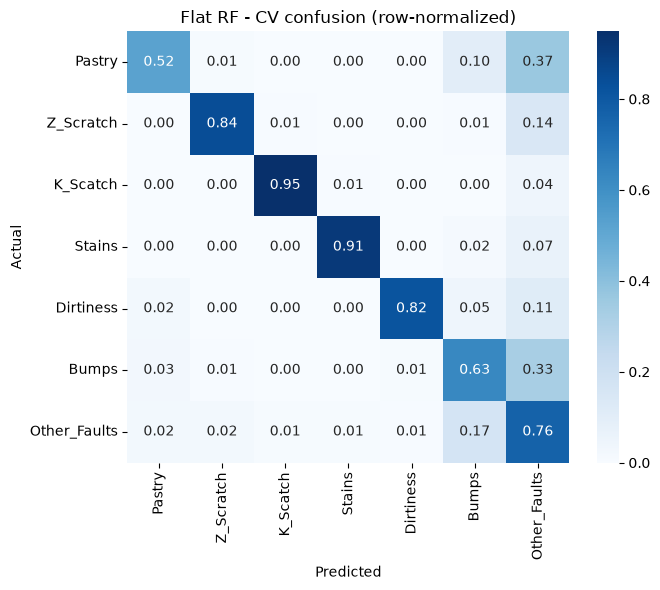

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)

oof_flat = cross_val_predict(rf, X_train, y_train, cv=cv)
print("Flat RF  CV Macro F1:", round(f1_score(y_train, oof_flat, average="macro"), 4))

cm_cv = pd.DataFrame(confusion_matrix(y_train, oof_flat, labels=FAULTS, normalize="true"),
                     index=FAULTS, columns=FAULTS)

plt.figure(figsize=(7, 6))
sns.heatmap(cm_cv, annot=True, fmt=".2f", cmap="Blues")
plt.title("Flat RF - CV confusion (row-normalized)")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.show()

## 3. 혼동 기반 계층적 군집으로 그룹 결정

- 유사도 `S[i, j]` = (i→j 오분류율 + j→i 오분류율) / 2 (대칭화)
- 거리 `D = 1 - S` 로 두고 average linkage 계층 군집
- **기준**: 대칭 혼동률이 평균 5% 이상(거리 ≤ 0.95)인 클래스끼리만 묶는다. → `THRESHOLD`를 바꿔 묶음 정도를 조절할 수 있음

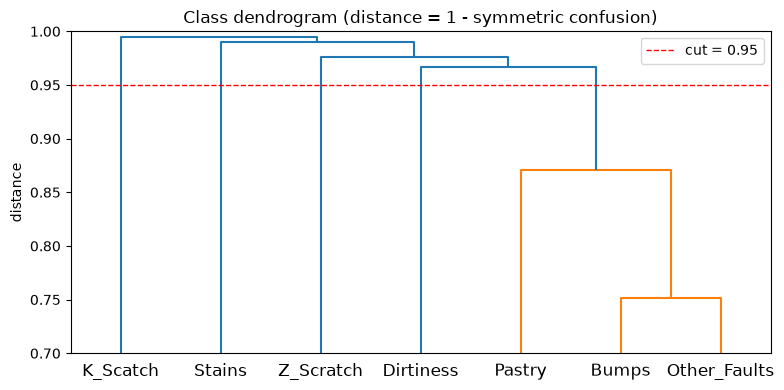

G_Pastry+Bumps+Other_Faults         <- ['Pastry', 'Bumps', 'Other_Faults']
Z_Scratch                           <- ['Z_Scratch']
K_Scatch                            <- ['K_Scatch']
Stains                              <- ['Stains']
Dirtiness                           <- ['Dirtiness']


In [4]:
S = ((cm_cv + cm_cv.T) / 2).values
D = 1 - S
np.fill_diagonal(D, 0)

Z = linkage(squareform(D, checks=False), method="average")

THRESHOLD = 0.95
plt.figure(figsize=(8, 4))
dendrogram(Z, labels=FAULTS, color_threshold=THRESHOLD)
plt.axhline(THRESHOLD, color="r", ls="--", lw=1, label=f"cut = {THRESHOLD}")
plt.ylim(0.7, 1.0)
plt.title("Class dendrogram (distance = 1 - symmetric confusion)")
plt.ylabel("distance"); plt.legend()
plt.tight_layout(); plt.show()

cluster_id = fcluster(Z, t=THRESHOLD, criterion="distance")
groups = {}
for cls, cid in zip(FAULTS, cluster_id):
    groups.setdefault(cid, []).append(cls)

# 그룹 이름: 단일 클래스면 클래스명 그대로, 묶인 그룹은 G_ + 구성원
GROUPS = {(members[0] if len(members) == 1 else "G_" + "+".join(members)): members
          for members in groups.values()}
for g, members in GROUPS.items():
    print(f"{g:35s} <- {members}")

결과적으로 **Pastry / Bumps / Other_Faults** 가 하나의 "혼동 그룹"으로 묶이고, 나머지(Z_Scratch, K_Scatch, Stains, Dirtiness)는 단독 그룹이 된다.

- Level 1: 5개 그룹 분류 (단독 4개 + 혼동 그룹 1개)
- Level 2: 혼동 그룹 내부 3-class 분류 (Pastry vs Bumps vs Other_Faults)

그룹 간 피처 차이를 확인하기 위해 혼동 그룹 내부 클래스의 주요 피처 분포를 함께 본다.

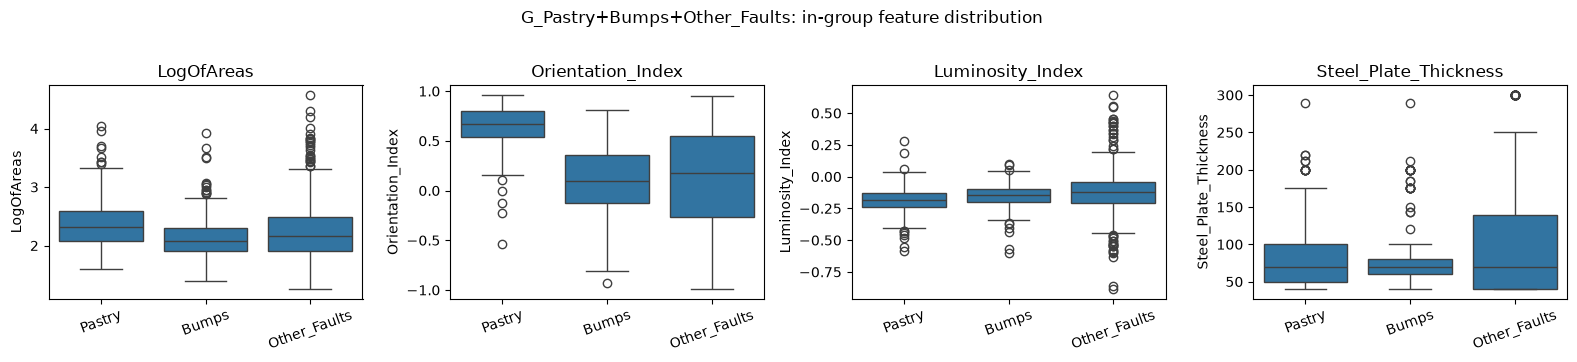

In [5]:
class_to_group = {c: g for g, ms in GROUPS.items() for c in ms}
g_train = y_train.map(class_to_group)

confused = [g for g, ms in GROUPS.items() if len(ms) > 1]
show_cols = ["LogOfAreas", "Orientation_Index", "Luminosity_Index", "Steel_Plate_Thickness"]
for g in confused:
    sub = pd.concat([X_train, y_train], axis=1)[g_train == g]
    fig, axes = plt.subplots(1, len(show_cols), figsize=(16, 3.5))
    for ax, col in zip(axes, show_cols):
        sns.boxplot(data=sub, x="Fault", y=col, ax=ax, order=GROUPS[g])
        ax.set_title(col); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=20)
    fig.suptitle(f"{g}: in-group feature distribution", y=1.02)
    plt.tight_layout(); plt.show()

## 4. 계층 분류기 구현

sklearn 추정기 형태(`fit` / `predict` / `predict_proba`)로 만들어서 `cross_val_predict` 등에 그대로 넣을 수 있게 한다.

- `level1`: 그룹 분류기 (전체 데이터)
- `level2`: 묶인 그룹마다 별도 분류기 (그 그룹 데이터만)
- `mode="hard"`: Level 1 그룹 → 그 그룹의 Level 2 예측
- `mode="soft"`: P(class) = P(group) × P(class | group), 단독 그룹은 P(class) = P(group)

In [6]:
class HierarchicalClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, groups, level1, level2, mode="soft"):
        self.groups = groups      # {group_name: [class, ...]}
        self.level1 = level1      # 그룹 분류기
        self.level2 = level2      # 그룹 내부 분류기 (그룹마다 clone 해서 사용)
        self.mode = mode          # "hard" | "soft"

    def fit(self, X, y):
        y = pd.Series(np.asarray(y), index=X.index)
        self.class_to_group_ = {c: g for g, ms in self.groups.items() for c in ms}
        self.classes_ = np.array(sorted(self.class_to_group_))

        self.level1_ = clone(self.level1).fit(X, y.map(self.class_to_group_))
        self.level2_ = {}
        for g, members in self.groups.items():
            if len(members) > 1:
                mask = y.isin(members)
                self.level2_[g] = clone(self.level2).fit(X[mask], y[mask])
        return self

    def predict_proba(self, X):
        p_group = pd.DataFrame(self.level1_.predict_proba(X), columns=self.level1_.classes_, index=X.index)
        proba = pd.DataFrame(0.0, index=X.index, columns=self.classes_)
        for g, members in self.groups.items():
            if len(members) == 1:
                proba[members[0]] = p_group[g]
            else:
                m = self.level2_[g]
                p_in = pd.DataFrame(m.predict_proba(X), columns=m.classes_, index=X.index)
                for c in members:
                    proba[c] = p_group[g] * p_in[c]
        return proba.values

    def predict(self, X):
        if self.mode == "soft":
            return self.classes_[self.predict_proba(X).argmax(axis=1)]

        g_pred = pd.Series(self.level1_.predict(X), index=X.index)
        pred = g_pred.map(lambda g: self.groups[g][0]).astype(object)  # 단독 그룹은 그대로 클래스
        for g, m in self.level2_.items():
            mask = g_pred == g
            if mask.any():
                pred[mask] = m.predict(X[mask])
        return pred.values

## 5. Flat vs 계층(Hard / Soft) 비교 — 5-fold CV (train) & Test

같은 base 모델로 비교해야 공정하므로 RandomForest / ExtraTrees / GradientBoosting 각각에 대해 flat과 계층 방식을 비교한다.

> 참고: 그룹 구성은 train 전체의 CV 결과로 한 번 정해 고정했다. 엄밀하게는 CV fold마다 그룹을 다시 정해야 하지만, 그룹 구조 자체는 안정적(클래스 수준 정보)이므로 여기서는 고정한다.

In [7]:
base_models = {
    "RandomForest":     RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "ExtraTrees":       ExtraTreesClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1),
    "GradientBoosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

def make_variants(base):
    return {
        "flat":      clone(base),
        "hier_hard": HierarchicalClassifier(GROUPS, base, base, mode="hard"),
        "hier_soft": HierarchicalClassifier(GROUPS, base, base, mode="soft"),
    }

rows, fitted, oof_preds = [], {}, {}
for base_name, base in base_models.items():
    for kind, model in make_variants(base).items():
        oof = cross_val_predict(model, X_train, y_train, cv=cv)
        model.fit(X_train, y_train)
        pred = model.predict(X_test)

        key = (base_name, kind)
        fitted[key], oof_preds[key] = model, oof
        rows.append({
            "base": base_name, "method": kind,
            "cv_acc":   accuracy_score(y_train, oof),
            "cv_f1":    f1_score(y_train, oof, average="macro"),
            "test_acc": accuracy_score(y_test, pred),
            "test_f1":  f1_score(y_test, pred, average="macro"),
        })

result = pd.DataFrame(rows)
result.round(4)

,base,method,cv_acc,cv_f1,test_acc,test_f1
0,RandomForest,flat,0.7687,0.7920,0.8098,0.8102
1,RandomForest,hier_hard,0.7674,0.7929,0.7866,0.8002
2,RandomForest,hier_soft,0.7706,0.7997,0.7892,0.8093
3,ExtraTrees,flat,0.7700,0.7949,0.7866,0.8035
4,ExtraTrees,hier_hard,0.7629,0.7931,0.7918,0.8081
5,ExtraTrees,hier_soft,0.7687,0.7949,0.7918,0.8122
6,GradientBoosting,flat,0.7777,0.7912,0.7892,0.8052
7,GradientBoosting,hier_hard,0.7751,0.7948,0.7995,0.8069
8,GradientBoosting,hier_soft,0.7764,0.7974,0.7995,0.8069


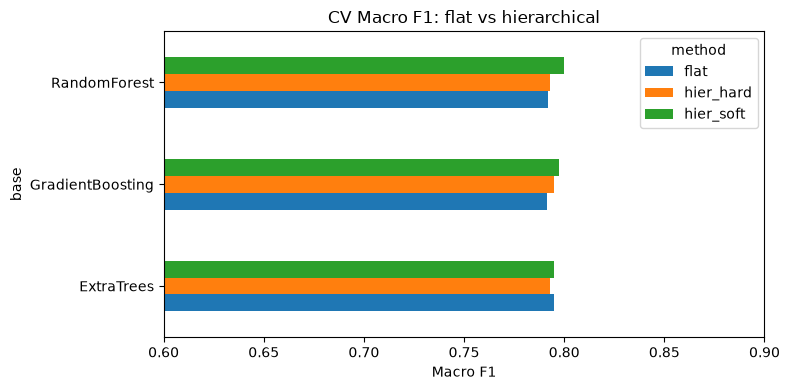

In [8]:
ax = result.pivot(index="base", columns="method", values="cv_f1").plot(kind="barh", figsize=(8, 4))
ax.set_title("CV Macro F1: flat vs hierarchical"); ax.set_xlabel("Macro F1"); ax.set_xlim(0.6, 0.9)
plt.tight_layout(); plt.show()

## 6. 최고 조합 분석

**CV Macro F1 기준**으로 최고 조합을 고른다 (test는 최종 확인용).

In [9]:
best = result.sort_values("cv_f1", ascending=False).iloc[0]
best_key = (best["base"], best["method"])
best_model = fitted[best_key]
y_pred = best_model.predict(X_test)

flat_pred = fitted[(best["base"], "flat")].predict(X_test)

print("Best:", best_key)
print(classification_report(y_test, y_pred, digits=3))

per_class = pd.DataFrame({
    "flat_f1": f1_score(y_test, flat_pred, labels=FAULTS, average=None),
    "best_f1": f1_score(y_test, y_pred,   labels=FAULTS, average=None),
}, index=FAULTS)
per_class["diff"] = per_class["best_f1"] - per_class["flat_f1"]
per_class.round(3)

Best: ('RandomForest', 'hier_soft')
              precision    recall  f1-score   support

       Bumps      0.724     0.679     0.701        81
   Dirtiness      1.000     0.818     0.900        11
    K_Scatch      0.973     0.910     0.940        78
Other_Faults      0.703     0.822     0.758       135
      Pastry      0.630     0.531     0.576        32
      Stains      0.923     0.857     0.889        14
   Z_Scratch      0.970     0.842     0.901        38

    accuracy                          0.789       389
   macro avg      0.846     0.780     0.809       389
weighted avg      0.798     0.789     0.790       389



,flat_f1,best_f1,diff
Pastry,0.566,0.576,0.010
Z_Scratch,0.932,0.901,-0.030
K_Scatch,0.947,0.940,-0.007
Stains,0.889,0.889,0.000
Dirtiness,0.818,0.900,0.082
Bumps,0.735,0.701,-0.035
Other_Faults,0.784,0.758,-0.026


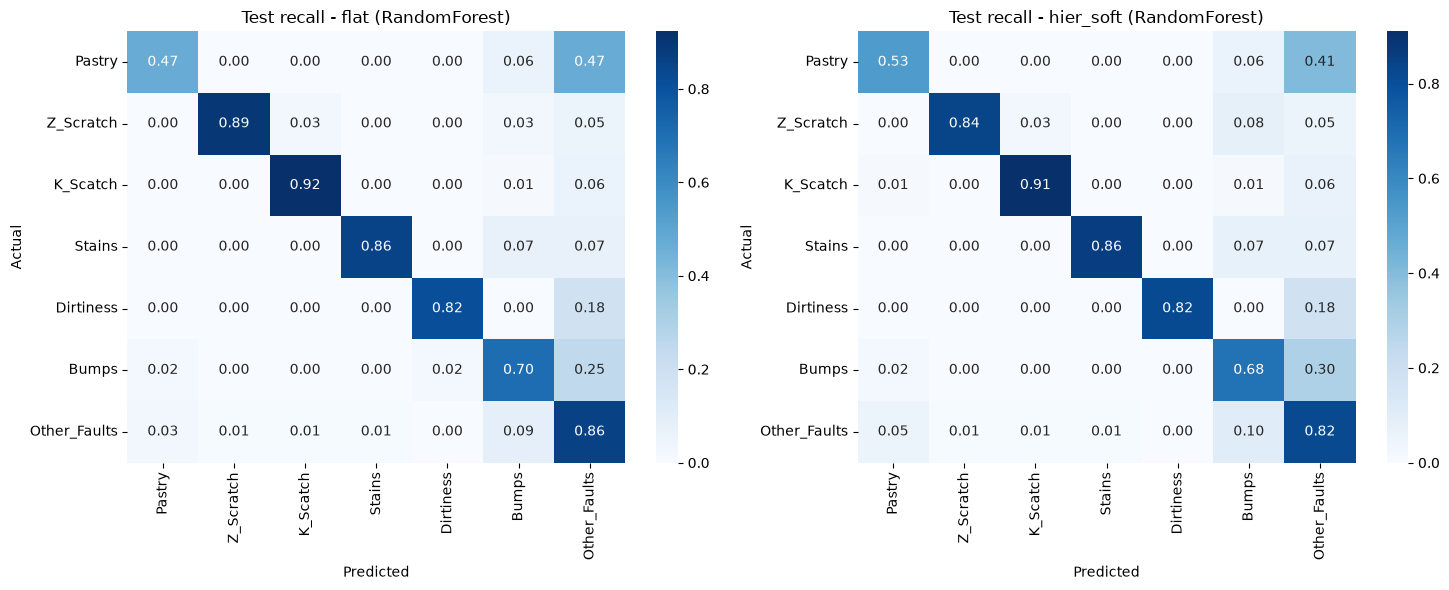

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (title, pred) in zip(axes, [(f"flat ({best['base']})", flat_pred),
                                    (f"{best['method']} ({best['base']})", y_pred)]):
    cm = confusion_matrix(y_test, pred, labels=FAULTS, normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=FAULTS, yticklabels=FAULTS, ax=ax)
    ax.set_title(f"Test recall - {title}"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

## 7. Level별 성능 분해 (어디서 틀리는가)

- **Level 1 정확도**: 그룹을 맞혔는가
- **Level 2 정확도 (조건부)**: 그룹을 맞힌 샘플 중, 그룹 내부 클래스까지 맞혔는가
- 전체 오류 = Level 1 오류 + (Level 1은 맞았지만) Level 2 오류

어느 Level이 병목인지 보면 다음 개선 방향(그룹 분류 피처 vs 그룹 내부 전용 피처/모델)을 정할 수 있다.

Level 1 (group) accuracy        : 0.9460
Level 1 (group) macro F1        : 0.9076
Level 2 [G_Pastry+Bumps+Other_Faults] acc | L1 correct : 0.7469  (n=245)

 correct                0.7866
L1 error (group)       0.0540
L2 error (in-group)    0.1594
dtype: float64


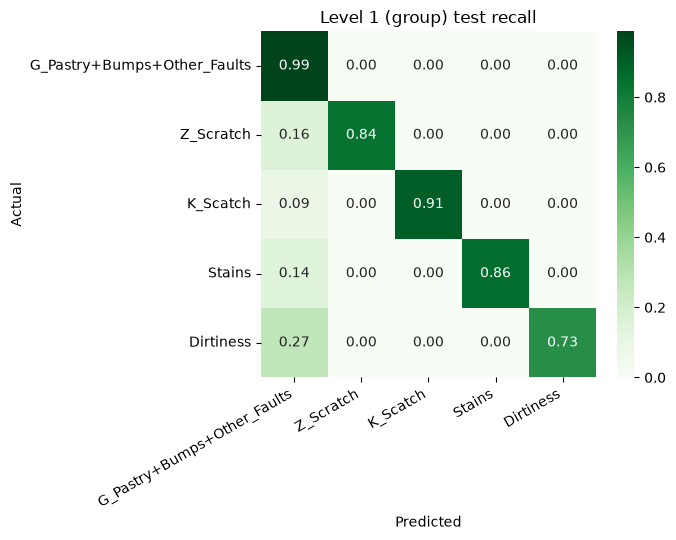

In [11]:
hier = fitted[(best["base"], "hier_hard")]
g_true = y_test.map(class_to_group)
g_pred = pd.Series(hier.level1_.predict(X_test), index=X_test.index)
c_pred = pd.Series(hier.predict(X_test), index=X_test.index)

l1_ok = g_true == g_pred
print(f"Level 1 (group) accuracy        : {l1_ok.mean():.4f}")
print(f"Level 1 (group) macro F1        : {f1_score(g_true, g_pred, average='macro'):.4f}")
for g in confused:
    in_g = l1_ok & (g_true == g)
    print(f"Level 2 [{g}] acc | L1 correct : {(c_pred[in_g] == y_test[in_g]).mean():.4f}  (n={in_g.sum()})")

err = pd.Series({
    "correct":            (c_pred == y_test).mean(),
    "L1 error (group)":   (~l1_ok).mean(),
    "L2 error (in-group)": (l1_ok & (c_pred != y_test)).mean(),
})
print("\n", err.round(4))

group_labels = list(GROUPS)
cm_g = confusion_matrix(g_true, g_pred, labels=group_labels, normalize="true")
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm_g, annot=True, fmt=".2f", cmap="Greens", xticklabels=group_labels, yticklabels=group_labels)
plt.title("Level 1 (group) test recall"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

## 8. 정리 & 다음 단계

- 그룹은 **CV 혼동행렬 + 계층 군집**으로 데이터 기반으로 정했다. `THRESHOLD`를 높이면 Dirtiness 등도 혼동 그룹에 합류한다.
- 계층 방식이 flat보다 크게 낫지 않을 수 있다 — 트리 앙상블은 이미 내부적으로 클래스 경계를 잘 나누기 때문. 계층 구조의 진짜 이점은 **Level 2에 그룹 전용 설정을 줄 수 있다는 점**이다:
  - Level 2에만 `class_weight="balanced"` / 다른 모델 / 하이퍼파라미터 튜닝 적용
  - 그룹 내부를 잘 가르는 **전용 파생변수**(예: Pastry vs Bumps vs Other 차이가 큰 피처) 추가
  - Level 1 확률이 애매한 경우(예: max P(group) < 0.6) 수동 검사로 넘기는 reject 옵션
- 오류 분해에서 **Level 2 오류가 대부분**이면 혼동 그룹 내부 분류가 병목 → 그쪽 피처 엔지니어링에 집중하면 된다.